### Group information as table


..........


### Brief of Selected industry and organisation

..............

In [12]:
import os
from dotenv import load_dotenv
from googleapiclient.discovery import build
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
load_dotenv()
q = "Apple"
api_key= os.environ.get("yt-api")
APPLE_CHANNEL_ID = "UCE_M8A5yxnLfW0KghEeajjw"

youtube = build("youtube", "v3", developerKey=api_key)

request = youtube.search().list(
    part="snippet", q=q,
    channelId=APPLE_CHANNEL_ID,
    maxResults=20,
    type="video",
    order="relevance"

        )

response = request.execute()

video_ids = []
for item in response.get("items", []):
    if "videoId" in item.get("id", {}):
        video_ids.append(item["id"]["videoId"])

stat_request = youtube.videos().list(
    part="snippet,statistics",
    id=",".join(video_ids)
)

stat_response = stat_request.execute()

for item in stat_response.get("items"):
  
    # stats = item.get("statistics")
    # print(stats)
    # print("*"*100)
    # print(stat_response)
    pass

videos=[]
for item in stat_response.get("items", []):
    stats = item.get("statistics", {})
    video_id = item["id"]#["videoId"]
    title = item["snippet"]["title"]
    view = int(stats.get("viewCount", 0))
    likes = int(stats.get("likeCount", 0))
    comment = int(stats.get("commentCount", 0))
    channel = item["snippet"]["channelTitle"]
    publish_time = item["snippet"]["publishedAt"]

    videos.append({
        "title":title,
        "views":view,
        "likes":likes,
        "comments":comment,
        "published":publish_time

    })


In [14]:
df = pd.DataFrame(videos)
df["Engagement ratio"] = (df["likes"]/df["views"])
df["published"] = pd.to_datetime(df["published"])
df["year"] = df["published"].dt.year

df.head(10)

,title,views,likes,comments,published,Engagement ratio,year
0,Apple Event September 9 2026: Introducing iPho...,50704518,509260,0,2026-09-09 18:25:05+00:00,0.010044,2026
1,Introducing the new iPhone 18 Pro,24043928,113563,0,2026-09-09 18:41:02+00:00,0.004723,2026
2,Introducing the new iPhone Duo,32416812,147202,0,2026-09-09 18:33:34+00:00,0.004541,2026
3,AirPods Pro 3,3313541,40848,0,2025-09-09 18:40:14+00:00,0.012328,2025
4,The new Mac mini with M6,34719975,38099,0,2026-08-25 13:33:48+00:00,0.001097,2026
5,Introducing Apple Creator Studio,710346,20749,0,2026-01-13 17:10:41+00:00,0.029210,2026
6,Welcome Apple HomeView: Designed for life at h...,6855012,49317,0,2026-10-13 13:12:01+00:00,0.007194,2026
7,iPhone 17e: A Powerful iPhone at a Great Price,16801751,61629,0,2026-03-02 14:12:04+00:00,0.003668,2026
8,"Apple Event — September 9, 2025",32077829,498847,0,2025-09-09 18:19:02+00:00,0.015551,2025
9,Apple WWDC 2026 June 8: Introducing Siri AI an...,9070548,169947,0,2026-06-08 18:23:18+00:00,0.018736,2026


In [15]:
total_views = df["views"].sum()
avg_views = df["views"].mean()
avg_likes = df["likes"].mean()
avg_comments = df["comments"].mean()
print("Total views:", total_views)
print("avg_views:", round(avg_views, 0))
print("avg_likes:", round(avg_likes, 0))
print("avg_comments:", avg_comments)
# df2 = pd.DataFrame([{"total_views":total_views, "avg_views":round(avg_views, 0)}])

top5 = df.sort_values("views", ascending=False).head(5)

# Most-viewed video
most_viewed = df.loc[df["views"].idxmax()]
print("\nMost-viewed video:")
print(most_viewed["title"])
print("Views:", most_viewed["views"])


# Most-liked video
most_liked = df.loc[df["likes"].idxmax()]
print("\nMost-liked video:")
print(most_liked["title"])
print("Likes:", most_liked["likes"])


# Top 5 videos by views
print(top5[["title", "views"]].to_string(index=False))


Total views: 229934617
avg_views: 12101822.0
avg_likes: 108300.0
avg_comments: 0.0

Most-viewed video:
Apple Event September 9 2026: Introducing iPhone Duo and more
Views: 50704518

Most-liked video:
Apple Event September 9 2026: Introducing iPhone Duo and more
Likes: 509260
                                                        title    views
Apple Event September 9 2026: Introducing iPhone Duo and more 50704518
                                     The new Mac mini with M6 34719975
                               Introducing the new iPhone Duo 32416812
                              Apple Event — September 9, 2025 32077829
                            Introducing the new iPhone 18 Pro 24043928


In [16]:

top10 = df.sort_values("views", ascending=False).head(10).copy()

## Visualizations

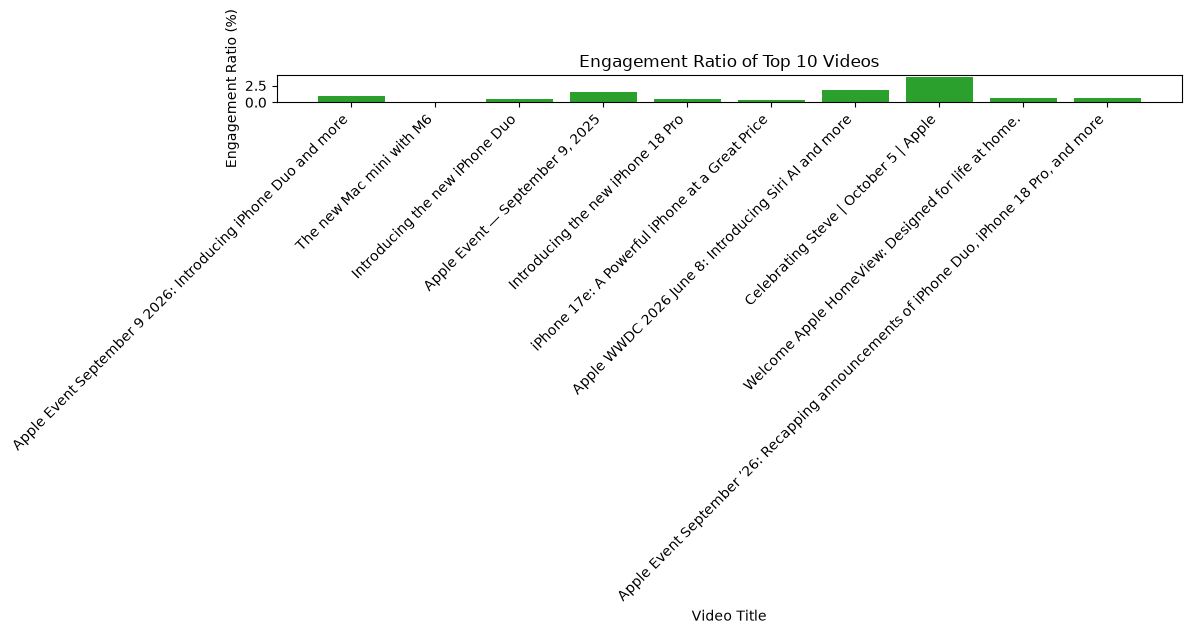

In [17]:
# Engagement ratio for the top 10 videos by views
plt.figure(figsize=(12, 6))
plt.bar(
    top10["title"],
    top10["Engagement ratio"] * 100,
    color="tab:green"
)

plt.title("Engagement Ratio of Top 10 Videos")
plt.xlabel("Video Title")
plt.ylabel("Engagement Ratio (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

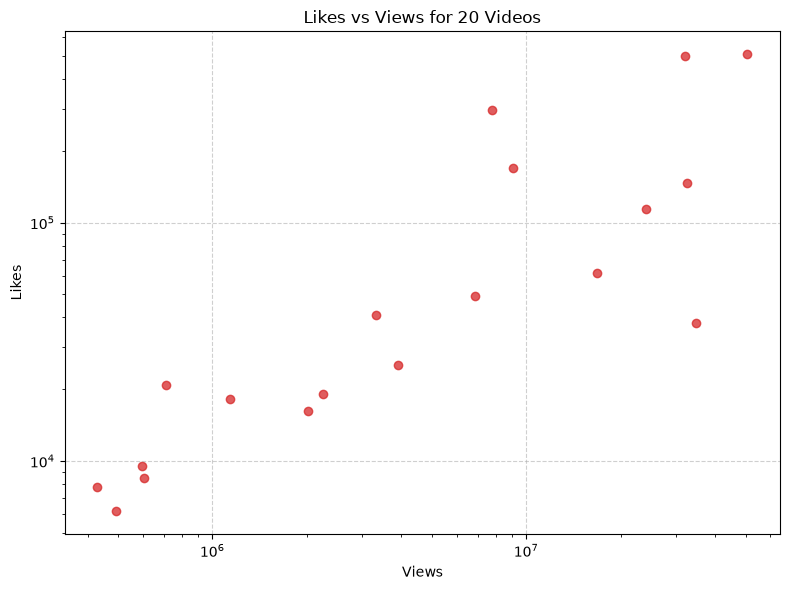

In [18]:
# Likes vs views for all 20 videos
plt.figure(figsize=(8, 6))
plt.scatter(
    df["views"],
    df["likes"],
    color="tab:red",
    alpha=0.75
)
plt.xscale("log")
plt.yscale("log")
plt.title("Likes vs Views for 20 Videos")
plt.xlabel("Views")
plt.ylabel("Likes")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

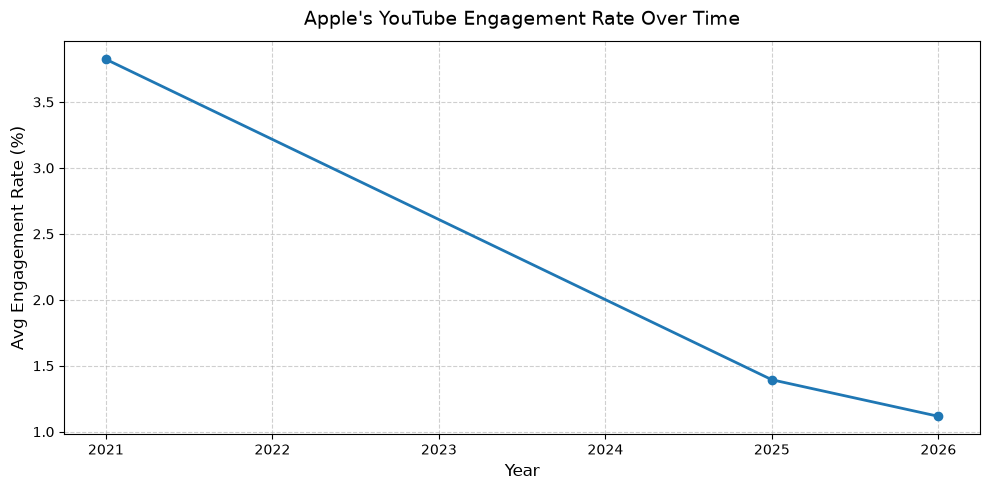

In [19]:
# Yearly Trend
yearly_engagement = df.groupby("year")["Engagement ratio"].mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(
    yearly_engagement.index,
    yearly_engagement.values,
    marker="o",
    linestyle="-",
    color="tab:blue",
    linewidth=2,
    markersize=6
)

plt.title("Apple's YouTube Engagement Rate Over Time", fontsize=14, pad=12)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Avg Engagement Rate (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## Problem
Problem description

## Solution and Recommendation
